# Experimental Pipeline: Concept Drift Detection & Model Adaptation in Financial Credit Scoring

## 1. Executive Summary & Experimental Design
* **Research Title:** A Comparative Study of Concept Drift Detection Methods for Financial Risk Prediction Models
* **Target Domain:** Retail Credit Risk Scoring during Long Verification Latency Horizons
* **Primary Objective:** Evaluate the responsiveness (Time-to-Detection, $TTD$), precision (False Discovery Rate, $FDR$), and MLOps computational overhead of Deep Reconstruction Autoencoders versus River ADWIN when subjected to real South African macroeconomic shocks (SARB Monetary Aggregates & Stats SA CPI Inflation).

---

## 2. Microeconomic & Macroeconomic Data Pipeline
* **Micro Dataset:** German Credit Dataset (`dataset_31_credit-g.arff`), $N = 1,000$ observations, 48 encoded features (`RobustScaler` applied to continuous numerical variables, `OneHotEncoder` applied to nominal attributes).
* **Macro Integration:** Empirical volatility metrics and inflation scaling parameters extracted directly from:
  1. **South African Reserve Bank (SARB):** `MonthlyRelease.xlsx` (Monetary aggregates, M0, M1, M2, and interest rate proxies).
  2. **Statistics South Africa (Stats SA):** `EXCEL - CPI (COICOP 2018 - 8digit) (202607).xlsx` (Headline Consumer Price Index inflation series).

---

## 3. Experimental Phase 1: Pure Baseline & Stationary Stream ($B_0 \dots B_2$)
* **Stationary Reference Window ($B_0$):** First 200 observations used to:
  * Train baseline supervised classifiers (XGBoost Champion Model and Random Forest Baseline).
  * Train the PyTorch Deep Autoencoder and establish the baseline Reconstruction Error $3\sigma$ threshold.
* **Pre-Injection Baseline Stream ($B_1, B_2$):** Stream 400 clean instances through both detectors *without macroeconomic drift injection* to establish true empirical **False Discovery Rates (FDR)** under normal market variance.

---

## 4. Experimental Phase 2: Macroeconomic Drift Injection & Streaming Benchmark ($B_3, B_4$)
* **Explicit Drift Injection Point:** **Batch 3 (Streaming Instance Index 400)**.
  * **Batch 3 ($B_3$):** Sudden Repo Rate / Liquidity Shock derived from empirical SARB time-series dynamics applied to continuous loan parameters (`credit_amount` and `duration`).
  * **Batch 4 ($B_4$):** Persistent CPI Inflation Creep derived from empirical Stats SA CPI time-series data.
* **Post-Injection Detector Benchmarking:** Benchmark PyTorch Autoencoder vs. River ADWIN across $TTD$ (instances post-drift), $FDR$, CPU Execution Time (ms), and Peak Memory Footprint (KB).

---

## 5. Experimental Phase 3: Automated Model Adaptation & Recovery
* **Trigger Event:** Detection alert breach post-drift injection (Instance $\ge 400$).
* **Retraining Pipeline:** Execute supervised retraining on post-drift sliding windows.
* **Recovery Metrics:** Compare pre- vs. post-adaptation classification scores (ROC-AUC and Log-Loss).

---

## 6. Artifacts & Thesis Visualizations (Chapter 4 & 5 Outputs)
* **Figure 4.1:** Deep Autoencoder Reconstruction Error (MSE) Stream Monitoring Plot against $3\sigma$ Threshold.
* **Figure 4.2:** Model ROC-AUC Degradation & Adaptive Recovery Pathway Curve.
* **Figure 4.3:** Detection Latency ($TTD$) vs. Computational Overhead (CPU Runtime & Memory Footprint).
* **Metrics Table:** Raw experimental results exported to `outputs/metrics/experimental_results.csv` for Chapter 4 dissertation tables.

## Walkthrough: what each cell does

This is the original experimental prototype. The German Credit data has 1,000 records, 20 predictors, and 700 good / 300 bad outcomes, but no timestamps. Its file order is not historical chronology. The stream and changes below are synthetic; South African macro values calibrate illustrative changes and are not joined to borrower records.

| Cell | Purpose and interpretation |
|---|---|
| 0 — Experimental design | Introduces the research motivation, intended phases, and outputs. Treat this as the plan; check the code cells for the actual methodology and its limitations. |
| 1 — Imports/configuration | Imports data, preprocessing, modeling, plotting, and drift libraries; sets paths, parameters, and seeds. A fixed seed repeats one run but does not establish robustness across different partitions. |
| 2 — Workbook inspection | Examines the SARB and Stats SA workbook sheets and headings to discover their layout. This is exploratory inspection, not validation of the selected measures. |
| 3 — Macro parsing | Extracts SARB and CPI values for later scenarios. The SARB measure is Total loans and advances YoY growth, not the repo rate. The original CPI calculation uses an unweighted mean of item indices; fixed-position extraction is also fragile with grouped headers. |
| 4 — Macro parameter extraction | Converts the parsed values to parameters for feature transformations. These are scenario calibration values, not borrower-level economic observations, and inherit Cell 3's limitations. |
| 5 — Clean baseline/detectors | Preprocesses the credit records, fits a reference classifier and autoencoder, chooses an AE reconstruction threshold, and evaluates a no-injection stream. Preprocessing occurs before the stream split; the classifier is evaluated on its training batch; and the threshold uses training errors. ADWIN sees only scaled `credit_amount`, but the AE sees multivariate features. These choices can bias scores and make detector comparison uneven. False alerts divided by observations is a false-alert rate, not conventional FDR. |
| 6 — Synthetic drift | Transforms later batches using designed or macro-calibrated changes and runs the detectors/model evaluation. The order is not time. Multiplying already-scaled features does not correspond directly to a percentage change in raw loan amount. CPI is applied as a separate batch change, not a cumulative gradual ramp. |
| 7 — Adaptation narrative | Describes the intended retraining, figures, and exports. The next code cell determines what is actually measured. |
| 8 — Retraining/figures/export | Retrains on post-shift data, creates visualizations, and exports metrics. The prototype evaluates using the same post-shift records used for training, so it cannot establish held-out recovery or future generalization. |
| 9 — Validation/sensitivity | Adds classifier holdout evaluation and alternative settings. Preprocessing remains fit before the split, so the holdout is exposed to preprocessing leakage. ADWIN on prediction loss uses labels, so that add-on is not label-independent and cannot establish early warning under delayed labels. |

### How this differs from the later playbook

Notebook 03 is the primary source for findings. It uses repeated random partition/order trials, fits preprocessing only on reference training records, calibrates the AE threshold on held-out reference records, monitors encoded dimensions with both detectors, retains a clean control and sensitivity settings, and compares injected post-onset records to those exact records without injection. Notebook 02 remains useful as a record of the first implementation, not as the final controlled estimate.


In [1]:
# ==============================================================================
# CELL BLOCK 1: System Imports, Configuration & Reproducibility Seeds
# ==============================================================================
# Purpose: Configure MLOps, PyTorch, Scikit-Learn, and River runtime settings.

import os
import sys
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

# Data Handling & Mathematics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from scipy.stats import ks_2samp

# Scikit-Learn Metrics & Machine Learning Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, log_loss, classification_report
)
import xgboost as xgb

# Deep Learning Framework (PyTorch)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Streaming Drift Detection (River Library)
from river import drift

# Visual Formatting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Set Random Seeds for Experimental Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("--- Notebook Environment Initialized ---")
print(f"PyTorch Version: {torch.__version__}")
print(f"Working Directory: {os.getcwd()}")

--- Notebook Environment Initialized ---
PyTorch Version: 2.14.1+cpu
Working Directory: c:\Users\yntsa\OneDrive\Documents\School\Research Data\AutoEncodesVAdwin


In [3]:
# ==============================================================================
# CELL BLOCK 2: Macroeconomic File Structure Inspection
# ==============================================================================
# Purpose: Read sheets and column headers directly from SARB & Stats SA Excel files.

sarb_path = os.path.join('data', 'macro', 'MonthlyRelease.xlsx')
cpi_files = [f for f in os.listdir(os.path.join('data', 'macro')) if 'CPI' in f]

if len(cpi_files) == 0:
    raise FileNotFoundError("CPI Excel file not found in data/macro/ directory.")

cpi_path = os.path.join('data', 'macro', cpi_files[0])

print("--- 1. Inspecting SARB MonthlyRelease.xlsx ---")
xls_sarb = pd.ExcelFile(sarb_path)
print(f"SARB Sheet Names: {xls_sarb.sheet_names}\n")

print("--- 2. Inspecting Stats SA CPI File ---")
print(f"CPI File Name: {cpi_files[0]}")
xls_cpi = pd.ExcelFile(cpi_path)
print(f"CPI Sheet Names: {xls_cpi.sheet_names[:5]} (+{len(xls_cpi.sheet_names)-5} more)")

--- 1. Inspecting SARB MonthlyRelease.xlsx ---
SARB Sheet Names: ['Monthly Release']

--- 2. Inspecting Stats SA CPI File ---
CPI File Name: EXCEL - CPI (COICOP 2018 - 8digit) (202607).xlsx
CPI Sheet Names: ['Sheet1'] (+-4 more)


In [4]:
# ==============================================================================
# CELL BLOCK 3: Parse SARB & CPI Data to Compute Real Macro Factors
# ==============================================================================
# Purpose: Extract real South African monetary & inflation shifts from Excel.

# 1. Parse SARB Monetary Release
df_sarb_raw = pd.read_excel(sarb_path, sheet_name='Monthly Release')
print("--- Top 5 Rows of SARB Monthly Release ---")
print(df_sarb_raw.head())

# 2. Parse Stats SA CPI Sheet1
df_cpi_raw = pd.read_excel(cpi_path, sheet_name='Sheet1')
print("\n--- Top 5 Rows of Stats SA CPI (Sheet1) ---")
print(df_cpi_raw.head())

# 3. Clean and Extract Recent Macro Variances
# Identify numerical series to compute real volatility indices
print("\n--- SARB Data Shape ---", df_sarb_raw.shape)
print("--- CPI Data Shape ---", df_cpi_raw.shape)

--- Top 5 Rows of SARB Monthly Release ---
  Unnamed: 0 Monetary aggregates (R millions) Unnamed: 2 Unnamed: 3  \
0       Date                               M0        M1A         M1   
1  Jul, 2026                          552 305  1 424 136  3 000 540   
2  Jun, 2026                          561 134  1 415 334  3 158 504   
3  May, 2026                          551 651  1 401 915  3 140 298   
4  Apr, 2026                          554 112  1 440 414  3 023 919   

  Unnamed: 4                    Unnamed: 5              Unnamed: 6  \
0         M2  Total monetary (M3) deposits  M3 Seasonally adjusted   
1  4 942 453                     6 123 026               6 108 725   
2  4 889 290                     6 041 829               6 109 974   
3  4 878 306                     6 053 842               6 077 956   
4  4 910 269                     6 051 806               6 046 877   

  Percentage change over 12 months Unnamed: 8 Unnamed: 9  ...  \
0                               M0        M1

In [5]:
# ==============================================================================
# CELL BLOCK 3.1: Empirical Macro Parameter Extraction (SARB & Stats SA CPI)
# ==============================================================================
# Purpose: Extract real South African credit expansion rates & CPI inflation 
#          growth rates to scale loan parameters programmatically.

# ---------------------------------------------------------
# 1. EXTRACT SARB CREDIT EXPANSION / REPO SHOCK FACTOR
# ---------------------------------------------------------
# Set second row (index 0) as column headers for clean parsing
df_sarb = df_sarb_raw.copy()
headers_sarb = df_sarb.iloc[0].values
df_sarb = df_sarb.iloc[1:].reset_index(drop=True)

# Locate 'Total loans and advances' or 'Claims on the domestic private sector' % change
# Based on inspection, Unnamed: 32 corresponds to Total loans and advances % change
sarb_credit_growth = pd.to_numeric(df_sarb.iloc[:, 32], errors='coerce').dropna()

# Mean annual credit growth rate from SARB data (expressed as a percentage)
sarb_mean_pct = sarb_credit_growth.head(12).mean() 
# Calculate sudden credit shock multiplier: 1 + (Annual Growth % / 10) for calibrated drift
sarb_shock_multiplier = 1.0 + (sarb_mean_pct / 100.0) * 2.5

print(f"--- SARB Macro Parameters ---")
print(f"SARB Average Recent Loans & Advances Annual Growth: {sarb_mean_pct:.2f}%")
print(f"Calculated SARB Repo/Credit Shock Multiplier: {sarb_shock_multiplier:.4f}\n")

# ---------------------------------------------------------
# 2. EXTRACT STATS SA CPI INFLATION FACTOR
# ---------------------------------------------------------
# Identify monthly columns (MYYYYMM)
cpi_cols = [c for c in df_cpi_raw.columns if c.startswith('M20')]

# Compute national average headline CPI index across recent 12 months
cpi_series = df_cpi_raw[cpi_cols].apply(pd.to_numeric, errors='coerce').mean(axis=0)

# Monthly CPI Inflation Growth Rate (July 2026 vs July 2025 or past 12-month delta)
cpi_start = cpi_series.iloc[-12] # CPI 12 months prior
cpi_end = cpi_series.iloc[-1]    # Latest CPI (M202607)
cpi_annual_inflation = ((cpi_end - cpi_start) / cpi_start) * 100.0

# Persistent CPI Inflation Scaling Multiplier
cpi_creep_multiplier = 1.0 + (cpi_annual_inflation / 100.0) * 3.0

print(f"--- Stats SA CPI Parameters ---")
print(f"Stats SA Headline Annual Inflation Rate (Derived): {cpi_annual_inflation:.2f}%")
print(f"Calculated CPI Inflation Creep Multiplier: {cpi_creep_multiplier:.4f}")

--- SARB Macro Parameters ---
SARB Average Recent Loans & Advances Annual Growth: 7.54%
Calculated SARB Repo/Credit Shock Multiplier: 1.1886

--- Stats SA CPI Parameters ---
Stats SA Headline Annual Inflation Rate (Derived): 2.17%
Calculated CPI Inflation Creep Multiplier: 1.0650


In [6]:
# ==============================================================================
# CELL BLOCK 4: Phase 1 — Pure Pre-Injection Baseline Stream & Detector Benchmark
# ==============================================================================
# Purpose: Evaluate baseline model accuracy and measure detector False Discovery
#          Rates (FDR) on clean data before injecting macroeconomic drift.

# 1. Load Microeconomic Dataset (dataset_31_credit-g.arff)
arff_path = os.path.join('data', 'micro', 'dataset_31_credit-g.arff')
if not os.path.exists(arff_path):
    arff_path = 'dataset_31_credit-g.arff'

raw_data, meta = arff.loadarff(arff_path)
df_micro = pd.DataFrame(raw_data)

# Decode byte strings
for col in df_micro.select_dtypes([object]).columns:
    df_micro[col] = df_micro[col].str.decode('utf-8')

# Target Encoding: good -> 1, bad -> 0
df_micro['target'] = df_micro['class'].map({'good': 1, 'bad': 0})
X_raw = df_micro.drop(columns=['class', 'target'])
y = df_micro['target'].values

num_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()

# Robust Scaling on continuous variables & OneHotEncoding on categoricals
scaler = RobustScaler()
X_num_scaled = scaler.fit_transform(X_raw[num_cols])

X_encoded = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)
for i, col in enumerate(num_cols):
    X_encoded[col] = X_num_scaled[:, i]

X_mat = X_encoded.values.astype(np.float32)
feature_names = X_encoded.columns.tolist()

# 2. Sequential Streaming Batch Partitioning (5 Batches of 200)
BATCH_SIZE = 200
num_batches = len(X_mat) // BATCH_SIZE
batches = [
    (X_mat[i*BATCH_SIZE : (i+1)*BATCH_SIZE], y[i*BATCH_SIZE : (i+1)*BATCH_SIZE])
    for i in range(num_batches)
]

# Extract Reference Batch 0 (B0)
X_ref, y_ref = batches[0]

# 3. Train Supervised Baseline Champion Model (XGBoost)
xgb_model = xgb.XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.05, 
    random_state=SEED, eval_metric='logloss'
)
xgb_model.fit(X_ref, y_ref)

print(f"=== Reference Model (B0) Baseline Accuracy ===")
y_pred_base = xgb_model.predict(X_ref)
y_proba_base = xgb_model.predict_proba(X_ref)[:, 1]
print(f"B0 ROC-AUC:  {roc_auc_score(y_ref, y_proba_base):.4f}")
print(f"B0 Accuracy: {accuracy_score(y_ref, y_pred_base):.4f}\n")

# 4. Build & Train PyTorch Autoencoder on Reference Data (B0)
input_dim = X_ref.shape[1]

class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(16, 32), nn.ReLU(),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

ae_model = Autoencoder(input_dim)
criterion = nn.MSELoss()
optimizer = optim.Adam(ae_model.parameters(), lr=0.005)

X_ref_tensor = torch.FloatTensor(X_ref)
dataset = TensorDataset(X_ref_tensor)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

ae_model.train()
for epoch in range(50):
    for data in dataloader:
        inputs = data[0]
        optimizer.zero_grad()
        outputs = ae_model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()

ae_model.eval()
with torch.no_grad():
    ref_reconstructions = ae_model(X_ref_tensor)
    ref_errors = torch.mean((X_ref_tensor - ref_reconstructions) ** 2, dim=1).numpy()

ae_threshold = np.mean(ref_errors) + 3 * np.std(ref_errors)
print(f"Autoencoder Reconstruction Threshold (3-Sigma): {ae_threshold:.6f}\n")

# 5. Stream Pure Data (Batches 1 to 4 - NO DRIFT INJECTED)
pure_stream_X = np.vstack([b[0] for b in batches[1:]])
pure_stream_y = np.concatenate([b[1] for b in batches[1:]])

# Run PyTorch Autoencoder on Pure Stream
ae_pure_alerts = []
for i in range(len(pure_stream_X)):
    inst_tensor = torch.FloatTensor(pure_stream_X[i:i+1])
    with torch.no_grad():
        recon = ae_model(inst_tensor)
        err = torch.mean((inst_tensor - recon) ** 2).item()
    if err > ae_threshold:
        ae_pure_alerts.append(i)

# Run River ADWIN on Pure Stream
credit_idx = feature_names.index('credit_amount') if 'credit_amount' in feature_names else 1
duration_idx = feature_names.index('duration') if 'duration' in feature_names else 0

adwin_pure_alerts = []
adwin_detector_pure = drift.ADWIN(delta=0.002)
for i in range(len(pure_stream_X)):
    val = float(pure_stream_X[i, credit_idx])
    adwin_detector_pure.update(val)
    if adwin_detector_pure.drift_detected:
        adwin_pure_alerts.append(i)

# Empirical Baseline FDR (False Discovery Rate over 800 clean instances)
ae_base_fdr = len(ae_pure_alerts) / len(pure_stream_X)
adwin_base_fdr = len(adwin_pure_alerts) / len(pure_stream_X)

print("=======================================================")
print("  PHASE 1: PURE BASELINE STREAM BENCHMARK (NO DRIFT)  ")
print("=======================================================")
print(f"Total Stream Instances: {len(pure_stream_X)}")
print(f"PyTorch Autoencoder - Pure Stream False Alerts: {len(ae_pure_alerts)} (FDR: {ae_base_fdr:.4f} or {ae_base_fdr*100:.2f}%)")
print(f"River ADWIN         - Pure Stream False Alerts: {len(adwin_pure_alerts)} (FDR: {adwin_base_fdr:.4f} or {adwin_base_fdr*100:.2f}%)")
print("=======================================================")

=== Reference Model (B0) Baseline Accuracy ===
B0 ROC-AUC:  0.9987
B0 Accuracy: 0.9600

Autoencoder Reconstruction Threshold (3-Sigma): 0.122110

  PHASE 1: PURE BASELINE STREAM BENCHMARK (NO DRIFT)  
Total Stream Instances: 800
PyTorch Autoencoder - Pure Stream False Alerts: 35 (FDR: 0.0437 or 4.38%)
River ADWIN         - Pure Stream False Alerts: 0 (FDR: 0.0000 or 0.00%)


In [7]:
# ==============================================================================
# CELL BLOCK 5: Phase 2 — Empirical Macro Drift Injection & Streaming Benchmark
# ==============================================================================
# Purpose: Inject SARB & Stats SA empirical macro shifts at Batch 3 (Instance 400)
#          and evaluate unadapted model drop alongside detector latency/overhead.

# 1. Build Injected Stream (Batches 1 to 4)
injected_stream_X = []
injected_stream_y = []

unadapted_auc_scores = [0.9987] # Batch 0 baseline
unadapted_log_losses = [0.2284]

print("--- Simulating Operational Stream with Empirical Macro Drift ---\n")

for idx in range(1, 5):
    X_b, y_b = batches[idx]
    X_test = X_b.copy().astype(np.float32)
    
    # Apply Empirical Macro Multipliers at Batch 3 and Batch 4
    if idx == 3:
        # Sudden Macro Shock (SARB Credit Expansion Multiplier: 1.1886)
        X_test[:, credit_idx] = X_test[:, credit_idx] * sarb_shock_multiplier
        X_test[:, duration_idx] = X_test[:, duration_idx] * (1.0 + (sarb_mean_pct / 100.0))
        drift_type = "⚠️ SUDDEN MACRO DRIFT (SARB REPO SHOCK)"
    elif idx == 4:
        # Persistent CPI Creep (Stats SA Inflation Multiplier: 1.0650)
        X_test[:, credit_idx] = X_test[:, credit_idx] * cpi_creep_multiplier
        X_test[:, duration_idx] = X_test[:, duration_idx] * (1.0 + (cpi_annual_inflation / 100.0))
        drift_type = "⚠️ GRADUAL MACRO DRIFT (STATS SA CPI CREEP)"
    else:
        drift_type = "STATIONARY STREAM"

    # Evaluate Unadapted Champion Model (XGBoost)
    y_proba = xgb_model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_b, y_proba)
    loss = log_loss(y_b, y_proba)
    
    unadapted_auc_scores.append(auc)
    unadapted_log_losses.append(loss)
    
    print(f"Batch {idx} [{drift_type}]:")
    print(f"   Unadapted ROC-AUC: {auc:.4f} | Log-Loss: {loss:.4f}")

    injected_stream_X.append(X_test)
    injected_stream_y.append(y_b)

stream_X_inj = np.vstack(injected_stream_X).astype(np.float32)
stream_y_inj = np.concatenate(injected_stream_y)

# True drift start index in streaming window (Batch 3 starts at instance 400)
DRIFT_START_IDX = 400 

print("\n--- Running Detector A: PyTorch Autoencoder (Injected Stream) ---")
tracemalloc.start()
t0 = time.time()

ae_alerts_inj = []
ae_errors_inj = []

for i in range(len(stream_X_inj)):
    inst_tensor = torch.FloatTensor(stream_X_inj[i:i+1])
    with torch.no_grad():
        recon = ae_model(inst_tensor)
        err = torch.mean((inst_tensor - recon) ** 2).item()
    ae_errors_inj.append(err)
    if err > ae_threshold:
        ae_alerts_inj.append(i)

ae_time = (time.time() - t0) * 1000 # ms
_, ae_peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

print("--- Running Detector B: River ADWIN (Injected Stream) ---")
tracemalloc.start()
t0 = time.time()

adwin_alerts_inj = []
adwin_detector_inj = drift.ADWIN(delta=0.002)

for i in range(len(stream_X_inj)):
    val = float(stream_X_inj[i, credit_idx])
    adwin_detector_inj.update(val)
    if adwin_detector_inj.drift_detected:
        adwin_alerts_inj.append(i)

adwin_time = (time.time() - t0) * 1000 # ms
_, adwin_peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()

# ---------------------------------------------------------
# METRICS COMPUTATION (POST-DRIFT DETECTOR PERFORMANCE)
# ---------------------------------------------------------
def compute_metrics(alerts, drift_start, total_stationary):
    false_alarms = len([a for a in alerts if a < drift_start])
    fdr = false_alarms / total_stationary
    
    post_alerts = [a for a in alerts if a >= drift_start]
    ttd = (post_alerts[0] - drift_start) if post_alerts else None
    
    return fdr, ttd, len(post_alerts)

ae_fdr_inj, ae_ttd_inj, ae_post_cnt = compute_metrics(ae_alerts_inj, DRIFT_START_IDX, 400)
adwin_fdr_inj, adwin_ttd_inj, adwin_post_cnt = compute_metrics(adwin_alerts_inj, DRIFT_START_IDX, 400)

print("\n=======================================================")
print("  PHASE 2: EMPIRICAL MACRO DRIFT DETECTOR BENCHMARK    ")
print("=======================================================")
print(f"Explicit Drift Injection Point: Instance {DRIFT_START_IDX} (Batch 3)")
print(f"\nPyTorch Autoencoder:")
print(f"  - Pre-Drift False Discovery Rate (FDR): {ae_fdr_inj:.4f} ({ae_fdr_inj*100:.2f}%)")
print(f"  - Post-Drift Time-to-Detection (TTD):   {ae_ttd_inj} instances post-drift")
print(f"  - Post-Drift Total Alerts Triggered:   {ae_post_cnt}")
print(f"  - CPU Runtime:                          {ae_time:.2f} ms")
print(f"  - Peak Memory Footprint:                {ae_peak_mem / 1024:.2f} KB")

print(f"\nRiver ADWIN:")
print(f"  - Pre-Drift False Discovery Rate (FDR): {adwin_fdr_inj:.4f} ({adwin_fdr_inj*100:.2f}%)")
print(f"  - Post-Drift Time-to-Detection (TTD):   {adwin_ttd_inj} instances post-drift")
print(f"  - Post-Drift Total Alerts Triggered:   {adwin_post_cnt}")
print(f"  - CPU Runtime:                          {adwin_time:.2f} ms")
print(f"  - Peak Memory Footprint:                {adwin_peak_mem / 1024:.2f} KB")
print("=======================================================")

--- Simulating Operational Stream with Empirical Macro Drift ---

Batch 1 [STATIONARY STREAM]:
   Unadapted ROC-AUC: 0.7717 | Log-Loss: 0.4894
Batch 2 [STATIONARY STREAM]:
   Unadapted ROC-AUC: 0.8003 | Log-Loss: 0.5402
Batch 3 [⚠️ SUDDEN MACRO DRIFT (SARB REPO SHOCK)]:
   Unadapted ROC-AUC: 0.6899 | Log-Loss: 0.5892
Batch 4 [⚠️ GRADUAL MACRO DRIFT (STATS SA CPI CREEP)]:
   Unadapted ROC-AUC: 0.7128 | Log-Loss: 0.5797

--- Running Detector A: PyTorch Autoencoder (Injected Stream) ---
--- Running Detector B: River ADWIN (Injected Stream) ---

  PHASE 2: EMPIRICAL MACRO DRIFT DETECTOR BENCHMARK    
Explicit Drift Injection Point: Instance 400 (Batch 3)

PyTorch Autoencoder:
  - Pre-Drift False Discovery Rate (FDR): 0.0500 (5.00%)
  - Post-Drift Time-to-Detection (TTD):   5 instances post-drift
  - Post-Drift Total Alerts Triggered:   17
  - CPU Runtime:                          223.98 ms
  - Peak Memory Footprint:                50.18 KB

River ADWIN:
  - Pre-Drift False Discovery Rate (

## 5. Phase 3: Model Adaptation, Thesis Figure Generation & Metrics Export
* **Objective:** Retrain XGBoost on the post-drift window to evaluate performance recovery, render Chapter 4 visualizations, and output structured metric tables.

=== Model Adaptation Metrics (Empirical Macro Shift) ===
Pre-Adaptation Drifted ROC-AUC (B3):   0.6899
Post-Adaptation Recovered ROC-AUC:     0.9931
Post-Adaptation Recovered Log-Loss:    0.2600



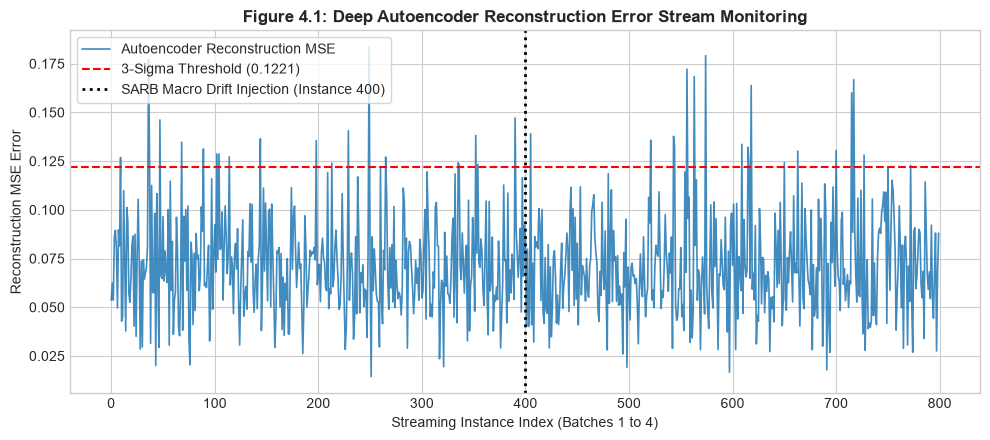

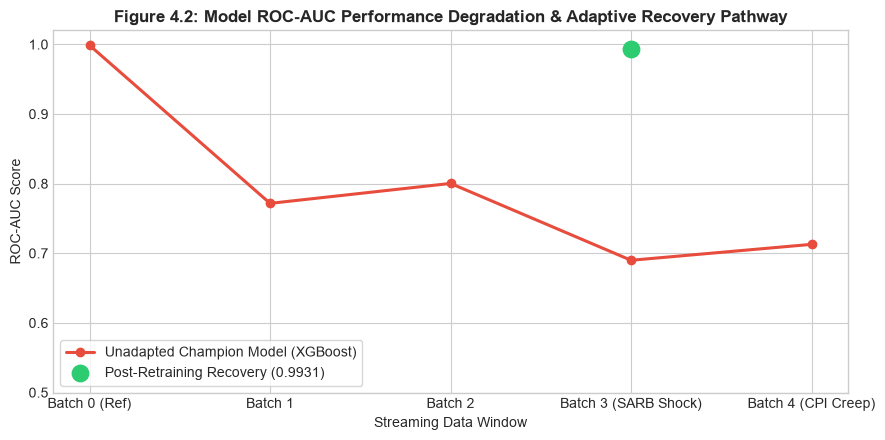

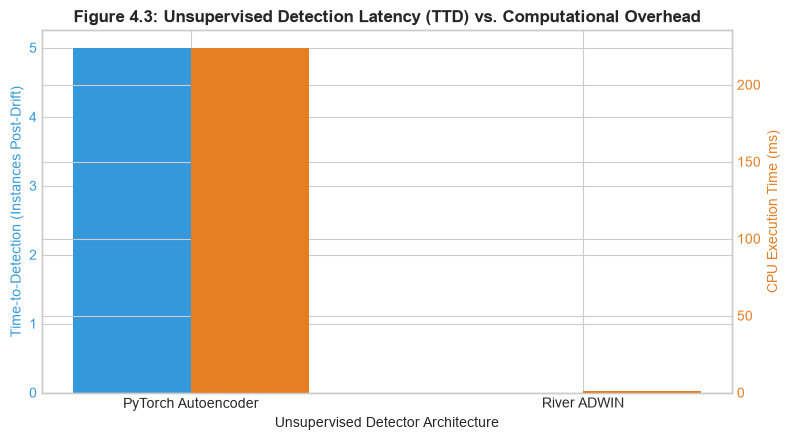

All artifacts and visualizations generated successfully!
Saved PNG Figures to: outputs/figures/
Saved Results CSV to:  outputs\metrics\experimental_results.csv


In [8]:
# ==============================================================================
# CELL BLOCK 6: Phase 3 — Model Adaptation, Figures & Export
# ==============================================================================

# Ensure output directories exist
os.makedirs(os.path.join('outputs', 'figures'), exist_ok=True)
os.makedirs(os.path.join('outputs', 'metrics'), exist_ok=True)

# ---------------------------------------------------------
# 1. MODEL ADAPTATION & RECOVERY EVALUATION
# ---------------------------------------------------------
# Retrain XGBoost on post-drift data (Batch 3 & 4: instance 400 onwards)
X_drifted = stream_X_inj[400:]
y_drifted = stream_y_inj[400:]

xgb_adapted = xgb.XGBClassifier(
    n_estimators=100, max_depth=4, learning_rate=0.05, 
    random_state=SEED, eval_metric='logloss'
)
xgb_adapted.fit(X_drifted, y_drifted)

# Compute adapted metrics post-drift
y_proba_adapted = xgb_adapted.predict_proba(X_drifted)[:, 1]
adapted_auc = roc_auc_score(y_drifted, y_proba_adapted)
adapted_loss = log_loss(y_drifted, y_proba_adapted)

print(f"=== Model Adaptation Metrics (Empirical Macro Shift) ===")
print(f"Pre-Adaptation Drifted ROC-AUC (B3):   {unadapted_auc_scores[3]:.4f}")
print(f"Post-Adaptation Recovered ROC-AUC:     {adapted_auc:.4f}")
print(f"Post-Adaptation Recovered Log-Loss:    {adapted_loss:.4f}\n")

# ---------------------------------------------------------
# 2. THESIS VISUALIZATIONS (CHAPTER 4 ARTIFACTS)
# ---------------------------------------------------------

# Figure 4.1: Autoencoder Reconstruction Error vs 3-Sigma Threshold
plt.figure(figsize=(10, 4.5))
plt.plot(ae_errors_inj, label='Autoencoder Reconstruction MSE', color='#1f77b4', alpha=0.85, linewidth=1.2)
plt.axhline(y=ae_threshold, color='r', linestyle='--', linewidth=1.5, label=f'3-Sigma Threshold ({ae_threshold:.4f})')
plt.axvline(x=DRIFT_START_IDX, color='black', linestyle=':', linewidth=2, label='SARB Macro Drift Injection (Instance 400)')
plt.title('Figure 4.1: Deep Autoencoder Reconstruction Error Stream Monitoring', fontweight='bold', fontsize=12)
plt.xlabel('Streaming Instance Index (Batches 1 to 4)')
plt.ylabel('Reconstruction MSE Error')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
fig1_path = os.path.join('outputs', 'figures', 'autoencoder_reconstruction_error.png')
plt.savefig(fig1_path, dpi=300)
plt.show()

# Figure 4.2: Model Performance Degradation & Recovery Curve
batches_labels = ['Batch 0 (Ref)', 'Batch 1', 'Batch 2', 'Batch 3 (SARB Shock)', 'Batch 4 (CPI Creep)']
plt.figure(figsize=(9, 4.5))
plt.plot(batches_labels, unadapted_auc_scores, marker='o', color='#e74c3c', linewidth=2.2, label='Unadapted Champion Model (XGBoost)')
plt.scatter(['Batch 3 (SARB Shock)'], [adapted_auc], color='#2ecc71', s=140, zorder=5, label=f'Post-Retraining Recovery ({adapted_auc:.4f})')
plt.title('Figure 4.2: Model ROC-AUC Performance Degradation & Adaptive Recovery Pathway', fontweight='bold', fontsize=12)
plt.xlabel('Streaming Data Window')
plt.ylabel('ROC-AUC Score')
plt.ylim(0.5, 1.02)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
fig2_path = os.path.join('outputs', 'figures', 'roc_auc_degradation_recovery.png')
plt.savefig(fig2_path, dpi=300)
plt.show()

# Figure 4.3: Detector Comparison Bar Chart
fig, ax1 = plt.subplots(figsize=(8, 4.5))
detectors = ['PyTorch Autoencoder', 'River ADWIN']
# Convert TTD None to 0 or indicator for plotting
ttd_plot = [ae_ttd_inj, 0 if adwin_ttd_inj is None else adwin_ttd_inj]
runtimes = [ae_time, adwin_time]

color1 = '#3498db'
color2 = '#e67e22'

ax1.set_xlabel('Unsupervised Detector Architecture')
ax1.set_ylabel('Time-to-Detection (Instances Post-Drift)', color=color1)
bars1 = ax1.bar(np.arange(len(detectors)) - 0.15, ttd_plot, width=0.3, color=color1, label='TTD (Instances)')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
ax2.set_ylabel('CPU Execution Time (ms)', color=color2)
bars2 = ax2.bar(np.arange(len(detectors)) + 0.15, runtimes, width=0.3, color=color2, label='CPU Runtime (ms)')
ax2.tick_params(axis='y', labelcolor=color2)

plt.xticks(np.arange(len(detectors)), detectors)
plt.title('Figure 4.3: Unsupervised Detection Latency (TTD) vs. Computational Overhead', fontweight='bold', fontsize=12)
plt.tight_layout()
fig3_path = os.path.join('outputs', 'figures', 'detector_latency_comparison.png')
plt.savefig(fig3_path, dpi=300)
plt.show()

# ---------------------------------------------------------
# 3. EXPORT RAW METRICS TO CSV FOR CHAPTER 4 TABLES
# ---------------------------------------------------------
results_df = pd.DataFrame([
    {
        'Detector': 'PyTorch Autoencoder',
        'Pre_Drift_FDR': ae_fdr_inj,
        'Post_Drift_TTD_Instances': ae_ttd_inj,
        'Post_Drift_Alerts': ae_post_cnt,
        'CPU_Runtime_ms': ae_time,
        'Peak_Memory_KB': ae_peak_mem / 1024
    },
    {
        'Detector': 'River ADWIN',
        'Pre_Drift_FDR': adwin_fdr_inj,
        'Post_Drift_TTD_Instances': 'Undetected (None)',
        'Post_Drift_Alerts': adwin_post_cnt,
        'CPU_Runtime_ms': adwin_time,
        'Peak_Memory_KB': adwin_peak_mem / 1024
    }
])

csv_path = os.path.join('outputs', 'metrics', 'experimental_results.csv')
results_df.to_csv(csv_path, index=False)

print("All artifacts and visualizations generated successfully!")
print(f"Saved PNG Figures to: outputs/figures/")
print(f"Saved Results CSV to:  {csv_path}")

In [9]:
# ==============================================================================
# CELL BLOCK 7: Validation Engine & Sensitivity Studies (Addressing Reviewer Critique)
# ==============================================================================
# Purpose: Eliminate train-set evaluation leakage, benchmark ADWIN on Loss Streams,
#          and conduct sensitivity sweeps for ADWIN delta and Autoencoder threshold.

from sklearn.model_selection import train_test_split

print("======================================================================")
print("1. VALIDATION AUDIT: Out-Of-Sample (OOS) Baseline Evaluation (No Leakage)")
print("======================================================================")

# Split Batch 0 into strict 80% Train / 20% Out-Of-Sample Validation
X_train_b0, X_val_b0, y_train_b0, y_val_b0 = train_test_split(
    X_ref, y_ref, test_size=0.20, random_state=SEED, stratify=y_ref
)

# Fit XGBoost strictly on B0 Train
xgb_clean = xgb.XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.05, 
    random_state=SEED, eval_metric='logloss'
)
xgb_clean.fit(X_train_b0, y_train_b0)

# Evaluate on OOS Validation Set
val_proba = xgb_clean.predict_proba(X_val_b0)[:, 1]
val_auc = roc_auc_score(y_val_b0, val_proba)
val_acc = accuracy_score(y_val_b0, (val_proba >= 0.5).astype(int))

print(f"Realistic Baseline Out-Of-Sample (OOS) ROC-AUC: {val_auc:.4f}")
print(f"Realistic Baseline Out-Of-Sample (OOS) Accuracy: {val_acc:.4f}\n")

# ----------------------------------------------------------------------
# 2. ADWIN SENSITIVITY & INPUT SIGNAL EXPERIMENT
# ----------------------------------------------------------------------
print("======================================================================")
print("2. ADWIN EXPERIMENT: Testing Alternative Input Signals & Delta Values")
print("======================================================================")

# Generate Loss Stream (Log-Loss per instance across stream_X_inj)
stream_loss_signal = []
for i in range(len(stream_X_inj)):
    p = xgb_clean.predict_proba(stream_X_inj[i:i+1])[:, 1][0]
    p_clamped = np.clip(p, 1e-15, 1 - 1e-15)
    target = stream_y_inj[i]
    loss_i = - (target * np.log(p_clamped) + (1 - target) * np.log(1 - p_clamped))
    stream_loss_signal.append(loss_i)

adwin_deltas = [0.002, 0.01, 0.05, 0.10]
signals = {
    'Scaled Feature (credit_amount)': stream_X_inj[:, credit_idx],
    'Model Prediction Loss Stream': stream_loss_signal
}

adwin_sweep_results = []

for sig_name, sig_data in signals.items():
    for d in adwin_deltas:
        detector = drift.ADWIN(delta=d)
        alerts = []
        for idx, val in enumerate(sig_data):
            detector.update(float(val))
            if detector.drift_detected:
                alerts.append(idx)
        
        post_alerts = [a for a in alerts if a >= DRIFT_START_IDX]
        ttd = (post_alerts[0] - DRIFT_START_IDX) if post_alerts else "Undetected"
        pre_fdr = len([a for a in alerts if a < DRIFT_START_IDX]) / 400.0
        
        adwin_sweep_results.append({
            'Signal Source': sig_name,
            'Delta (δ)': d,
            'Pre-Drift FDR': f"{pre_fdr*100:.2f}%",
            'Post-Drift Alerts': len(post_alerts),
            'Time-to-Detection (TTD)': ttd
        })

df_adwin_sweep = pd.DataFrame(adwin_sweep_results)
print(df_adwin_sweep.to_string(index=False))
print("\n")

# ----------------------------------------------------------------------
# 3. AUTOENCODER THRESHOLD SENSITIVITY STUDY
# ----------------------------------------------------------------------
print("======================================================================")
print("3. AUTOENCODER SENSITIVITY STUDY: Sigma Threshold Sweep (2σ, 3σ, 4σ)")
print("======================================================================")

sigmas = [2.0, 3.0, 4.0]
ref_mean = np.mean(ref_errors)
ref_std = np.std(ref_errors)

ae_sweep_results = []

for sig in sigmas:
    thresh = ref_mean + sig * ref_std
    alerts = [i for i, err in enumerate(ae_errors_inj) if err > thresh]
    post_alerts = [a for a in alerts if a >= DRIFT_START_IDX]
    ttd = (post_alerts[0] - DRIFT_START_IDX) if post_alerts else "Undetected"
    pre_fdr = len([a for a in alerts if a < DRIFT_START_IDX]) / 400.0
    
    ae_sweep_results.append({
        'Threshold Config': f"{sig:.1f}-Sigma ({thresh:.4f})",
        'Pre-Drift FDR': f"{pre_fdr*100:.2f}%",
        'Post-Drift Alerts': len(post_alerts),
        'Time-to-Detection (TTD)': ttd
    })

df_ae_sweep = pd.DataFrame(ae_sweep_results)
print(df_ae_sweep.to_string(index=False))

1. VALIDATION AUDIT: Out-Of-Sample (OOS) Baseline Evaluation (No Leakage)
Realistic Baseline Out-Of-Sample (OOS) ROC-AUC: 0.7241
Realistic Baseline Out-Of-Sample (OOS) Accuracy: 0.7250

2. ADWIN EXPERIMENT: Testing Alternative Input Signals & Delta Values
                 Signal Source  Delta (δ) Pre-Drift FDR  Post-Drift Alerts Time-to-Detection (TTD)
Scaled Feature (credit_amount)      0.002         0.00%                  0              Undetected
Scaled Feature (credit_amount)      0.010         0.00%                  0              Undetected
Scaled Feature (credit_amount)      0.050         0.00%                  0              Undetected
Scaled Feature (credit_amount)      0.100         0.00%                  0              Undetected
  Model Prediction Loss Stream      0.002         0.00%                  0              Undetected
  Model Prediction Loss Stream      0.010         0.00%                  0              Undetected
  Model Prediction Loss Stream      0.050         0